# Proyek Klasifikasi Gambar: Animal10
- **Email:** errietri555@gmail.com
- **ID Dicoding:** errietri555

## Import Semua Packages/Library yang Digunakan

In [5]:
!pip install tensorflow-hub==0.16.1 --no-deps
!pip install tf-keras kagglehub importlib_resources
!pip install tensorflowjs==4.20.0 --no-deps

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 5.4 MB/s eta 0:00:00


In [6]:
# ===== Pengaturan awal (harus sebelum import tensorflow & tensorflowjs) =====
import os
import sys
import types

os.environ["TF_USE_LEGACY_KERAS"] = "1"
sys.modules["tensorflow_decision_forests"] = types.ModuleType("tensorflow_decision_forests")

# ===== Library =====
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflowjs as tfjs
import kagglehub
import random
import hashlib

from google.colab import drive, files
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from PIL import Image
from collections import defaultdict



print("TensorFlow:", tf.__version__)
print("TFJS:", tfjs.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


TensorFlow: 2.21.0
TFJS: 4.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
tf.keras.utils.set_random_seed(42)

In [29]:
# mount google drive untuk menyipan model
drive.mount('/content/drive')

# Path Folder
BASE = "/content/drive/MyDrive/ColabNotebooks/submission_klasifikasi_gambar"
PATHS = {
    "saved_model": f"{BASE}/saved_model",
    "tflite": f"{BASE}/tflite",
    "tfjs": f"{BASE}/tfjs_model",
}

print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['notebooks.ipynb', 'saved_model', 'tfjs_model', 'tflite', 'requirements.txt', 'README.md']


## Data Preparation

### Data Loading


In [12]:
# Download latest version
path = kagglehub.dataset_download("paulbombay/animals10")

print("Path to dataset files:", path)

100%|██████████| 586M/586M [00:05<00:00, 109MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/paulbombay/animals10/versions/1


In [13]:
# cari folder train & test
folder = {}
for root, dirs, files in os.walk(path):
    for d in dirs:
        if d in ("train", "test"):
            folder[d] = os.path.join(root, d)
print(folder)

# hitung gambar per kelas
for nama, lokasi in folder.items():
    print(f"\n=== {nama} ===")
    total = 0
    for kelas in sorted(os.listdir(lokasi)):
        n = len(os.listdir(os.path.join(lokasi, kelas)))
        total += n
        print(f"{kelas:12} {n}")
    print("TOTAL:", total)

{'train': '/root/.cache/kagglehub/datasets/paulbombay/animals10/versions/1/images/train', 'test': '/root/.cache/kagglehub/datasets/paulbombay/animals10/versions/1/images/test'}

=== train ===
butterfly    1795
cat          1418
chicken      2633
cow          1586
dog          4134
elephant     1229
horse        2230
sheep        1547
spider       4098
squirrel     1583
TOTAL: 22253

=== test ===
butterfly    317
cat          250
chicken      465
cow          280
dog          729
elephant     217
horse        393
sheep        273
spider       723
squirrel     279
TOTAL: 3926


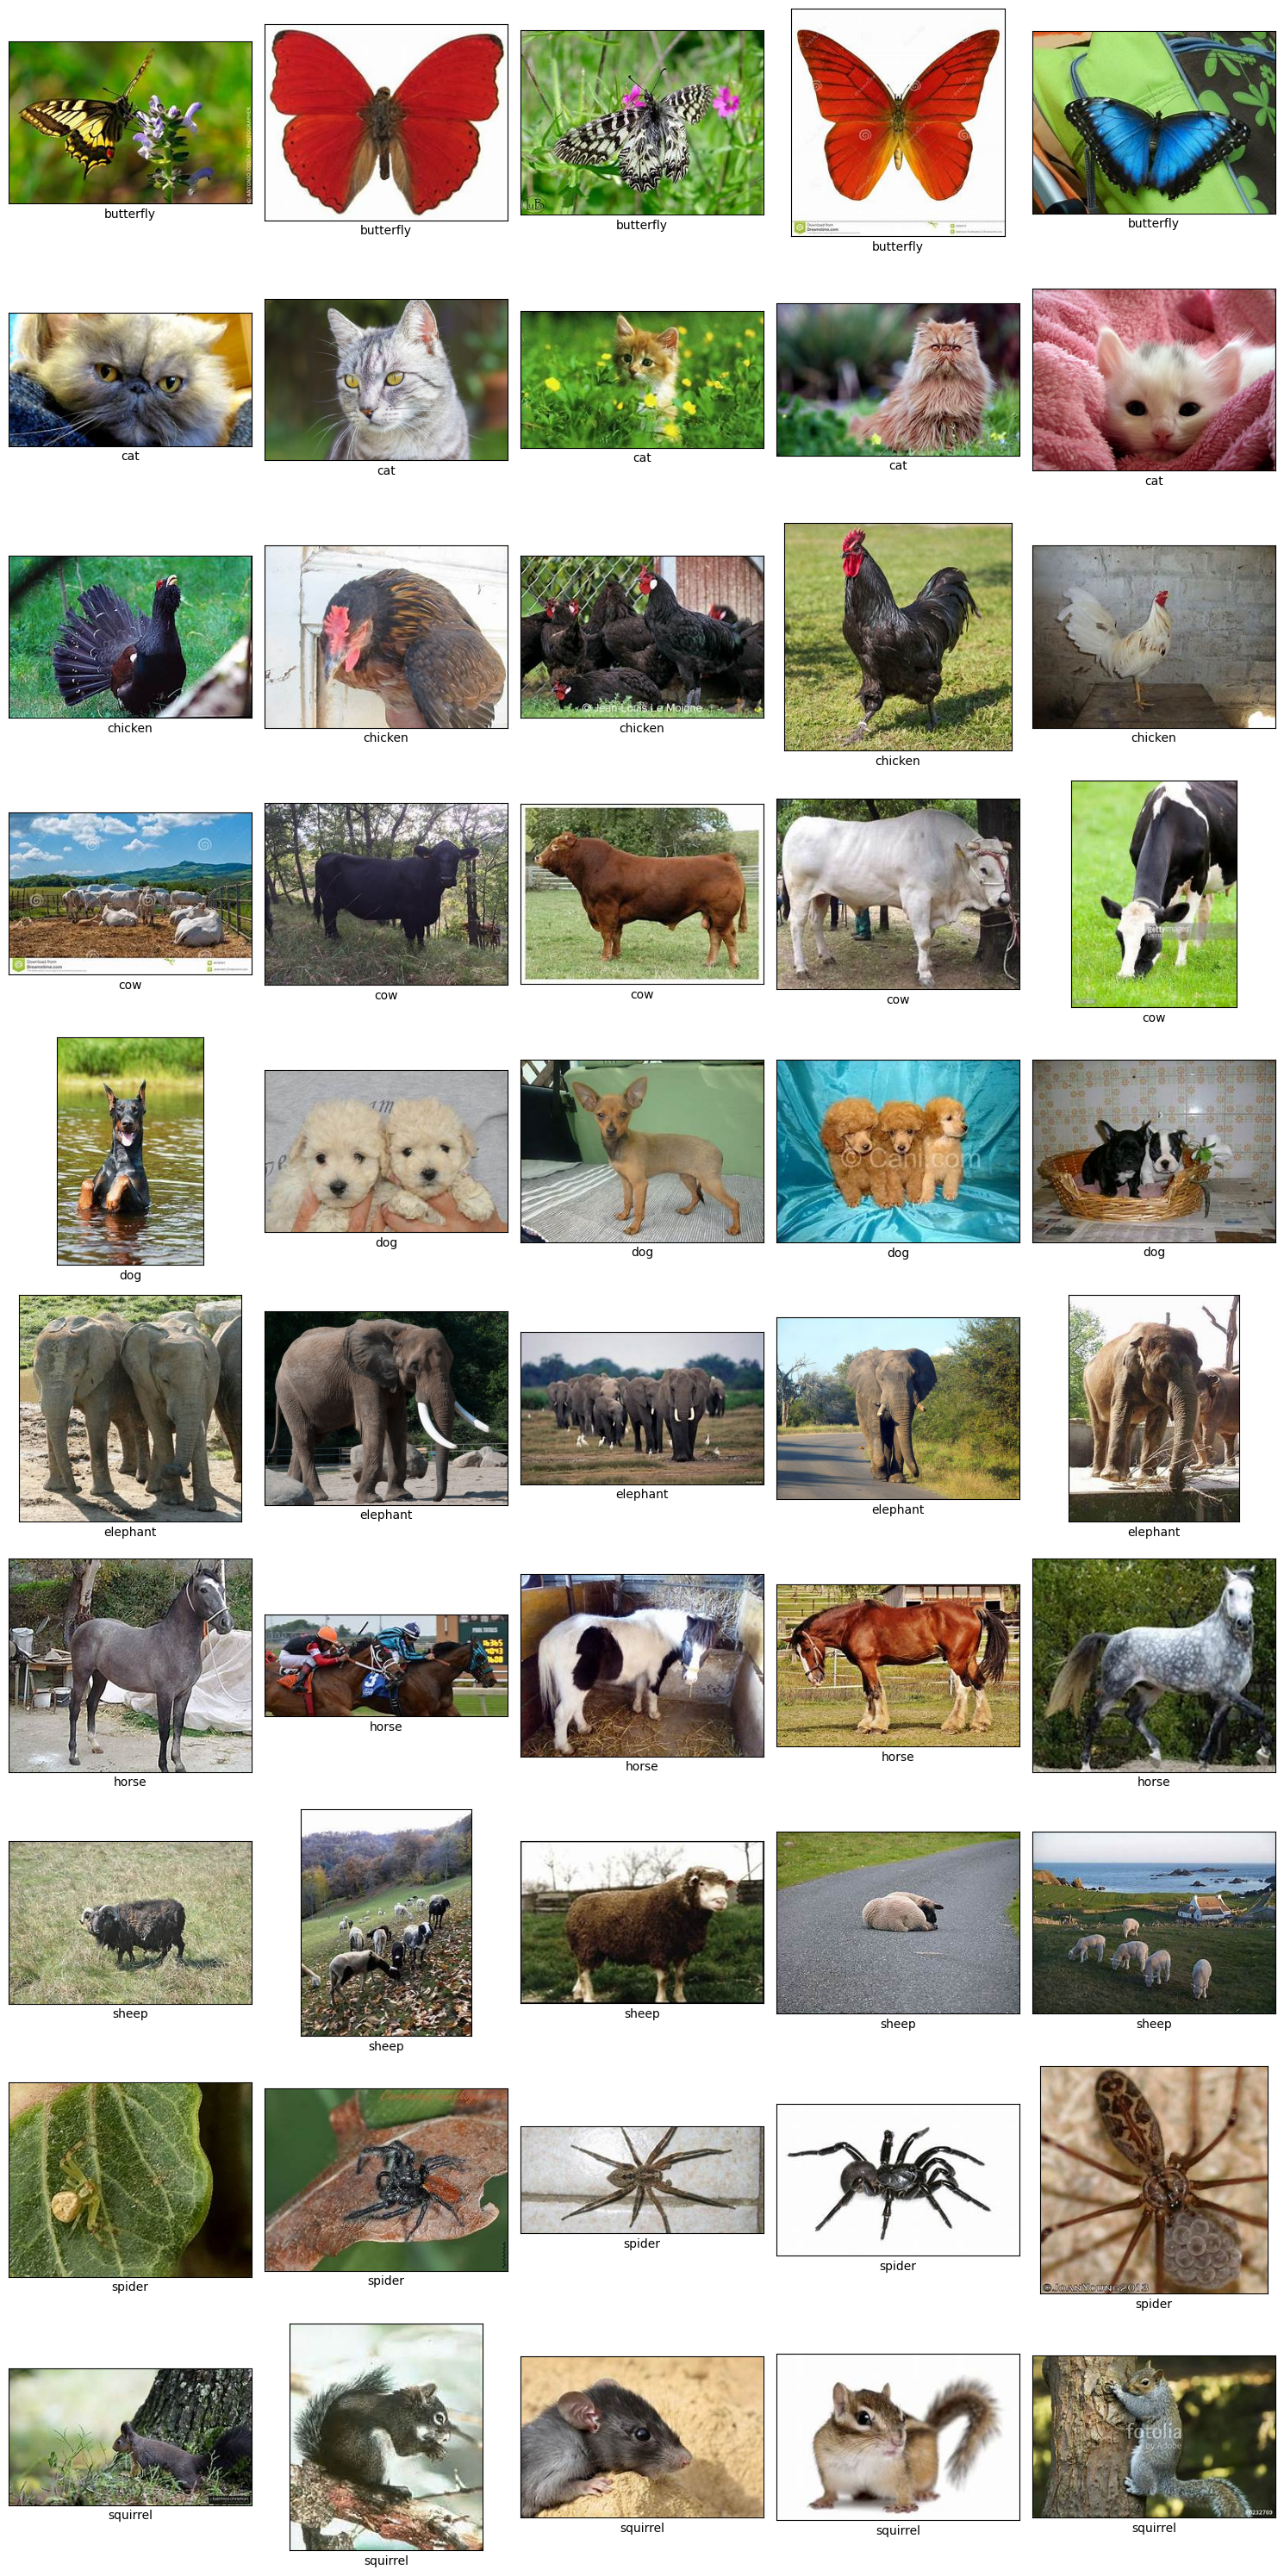

In [14]:
# Menampilkan sampel gambar acak dari semua kelas pada dataset asli (sebelum seleksi kelas dan split)
KELAS_SEMUA = sorted(os.listdir(folder["train"]))
JUMLAH = 5

fig, axs = plt.subplots(len(KELAS_SEMUA), JUMLAH, figsize=(15, 3 * len(KELAS_SEMUA)))

for i, kelas in enumerate(KELAS_SEMUA):
    d = os.path.join(folder["train"], kelas)
    contoh = np.random.choice(os.listdir(d), JUMLAH, replace=False)
    for j, nama in enumerate(contoh):
        img = Image.open(os.path.join(d, nama)).convert("RGB")
        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=kelas, xticks=[], yticks=[])

fig.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

In [15]:
random.seed(42)
KELAS = ["elephant", "butterfly", "cat", "chicken"]
OUT = "/content/data"
shutil.rmtree(OUT, ignore_errors=True)

for k in KELAS:
    f_train = sorted(os.listdir(f"{folder['train']}/{k}"))
    f_test = sorted(os.listdir(f"{folder['test']}/{k}"))
    random.shuffle(f_train)
    random.shuffle(f_test)

    bagian = {
        "train": (folder["train"], f_train[:1000]),
        "val":   (folder["train"], f_train[1000:1200]),
        "test":  (folder["test"],  f_test[:200]),
    }
    for nama, (src, files) in bagian.items():
        os.makedirs(f"{OUT}/{nama}/{k}", exist_ok=True)
        for f in files:
            shutil.copy(f"{src}/{k}/{f}", f"{OUT}/{nama}/{k}/{f}")

for nama in ["train", "val", "test"]:
    print(nama, {k: len(os.listdir(f"{OUT}/{nama}/{k}")) for k in KELAS})

train {'elephant': 1000, 'butterfly': 1000, 'cat': 1000, 'chicken': 1000}
val {'elephant': 200, 'butterfly': 200, 'cat': 200, 'chicken': 200}
test {'elephant': 200, 'butterfly': 200, 'cat': 200, 'chicken': 200}


#### Pra-pemrosesan Data

In [16]:
# Memeriksa kualitas dataset: file rusak, gambar duplikat, dan rentang ukuran gambar (tanpa mengubah file)
rusak = []
ukuran = []
hash_map = defaultdict(list)

for nama in ["train", "val", "test"]:
    for k in KELAS:
        d = f"{OUT}/{nama}/{k}"
        for f in os.listdir(d):
            p = os.path.join(d, f)
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    ukuran.append(im.size)
                with open(p, "rb") as fh:
                    hash_map[hashlib.md5(fh.read()).hexdigest()].append(p)
            except Exception:
                rusak.append(p)

duplikat = {h: ps for h, ps in hash_map.items() if len(ps) > 1}
lebar = [u[0] for u in ukuran]
tinggi = [u[1] for u in ukuran]

print("Total file dicek :", len(ukuran) + len(rusak))
print("File rusak       :", len(rusak))
print("Grup duplikat    :", len(duplikat))
print("Lebar  min/maks  :", min(lebar), "/", max(lebar))
print("Tinggi min/maks  :", min(tinggi), "/", max(tinggi))
print("Contoh rusak     :", rusak[:3])
print("Contoh duplikat  :", list(duplikat.values())[:2])

Total file dicek : 5600
File rusak       : 0
Grup duplikat    : 0
Lebar  min/maks  : 65 / 6720
Tinggi min/maks  : 64 / 6000
Contoh rusak     : []
Contoh duplikat  : []


In [17]:
# Memuat dataset dari folder train/val/test dan menyeragamkan ukuran gambar ke 150x150
IMG = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{OUT}/train", image_size=IMG, batch_size=BATCH,
    label_mode="categorical", shuffle=True, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{OUT}/val", image_size=IMG, batch_size=BATCH,
    label_mode="categorical", shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{OUT}/test", image_size=IMG, batch_size=BATCH,
    label_mode="categorical", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print(class_names, NUM_CLASSES)

Found 4000 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
['butterfly', 'cat', 'chicken', 'elephant'] 4


In [18]:
# Memeriksa bentuk batch dan membuktikan normalisasi mengubah piksel dari 0-255 menjadi 0-1
normalisasi = layers.Rescaling(1./255)

for x, y in train_ds.take(1):
    print("Bentuk batch gambar :", x.shape)    # (32, 150, 150, 3)
    print("Bentuk batch label  :", y.shape)    # (32, jumlah kelas)
    print("Piksel sebelum      : min", float(tf.reduce_min(x)), "maks", float(tf.reduce_max(x)))
    xn = normalisasi(x)
    print("Piksel sesudah      : min", float(tf.reduce_min(xn)), "maks", float(tf.reduce_max(xn)))

Bentuk batch gambar : (32, 224, 224, 3)
Bentuk batch label  : (32, 4)
Piksel sebelum      : min 0.0 maks 255.0
Piksel sesudah      : min 0.0 maks 1.0


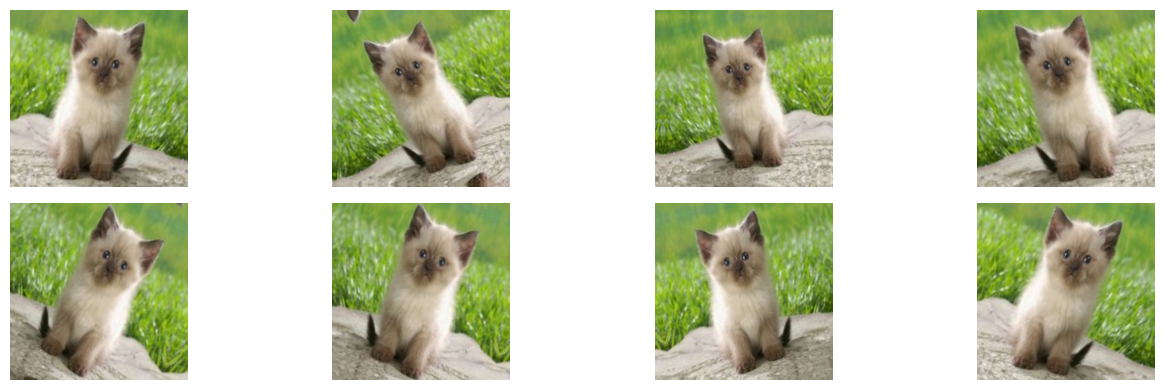

In [19]:
# Mendefinisikan augmentasi dan menampilkan 8 variasi satu gambar untuk memastikan hasilnya masih wajar
augmentasi = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentasi")

for x, y in train_ds.take(1):
    gambar = x[0:1]

plt.figure(figsize=(14, 4))
for i in range(8):
    aug = augmentasi(gambar, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.axis("off")
plt.tight_layout()
plt.show()

## Modelling

In [20]:
# Membangun arsitektur CNN: augmentasi -> normalisasi -> blok Conv2D + MaxPooling -> klasifikasi
def blok(filters):
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
    ]


model = Sequential(
    [layers.Input(shape=(*IMG, 3)), augmentasi, layers.Rescaling(1./255)]
    + blok(32) + blok(64) + blok(128) + blok(256)
    + [
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ],
    name="cnn_v2",
)

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "cnn_v2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 augmentasi (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 rescaling_1 (Rescaling)     (None, 224, 224, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 224, 224, 32)      864       
                                                                 
 batch_normalization (Batch  (None, 224, 224, 32)      128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 224, 224, 32)      0         
                                                                 
 conv2d_1 (Conv2D)           (None, 224, 224, 32)      9216      
                                                            

In [21]:
# Melatih model dengan callback: EarlyStopping (berhenti jika val_loss tidak membaik)
# dan ReduceLROnPlateau (menurunkan learning rate jika val_loss mandek)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks,
)

Epoch 1/50
125/125 [==============================] - 37s 199ms/step - loss: 1.0657 - accuracy: 0.5573 - val_loss: 2.0803 - val_accuracy: 0.2500 - lr: 0.0010
Epoch 2/50
125/125 [==============================] - 26s 200ms/step - loss: 0.8783 - accuracy: 0.6572 - val_loss: 1.5318 - val_accuracy: 0.3900 - lr: 0.0010
Epoch 3/50
125/125 [==============================] - 26s 203ms/step - loss: 0.7698 - accuracy: 0.7090 - val_loss: 3.5500 - val_accuracy: 0.3625 - lr: 0.0010
Epoch 4/50
125/125 [==============================] - 27s 209ms/step - loss: 0.6911 - accuracy: 0.7505 - val_loss: 2.0986 - val_accuracy: 0.4750 - lr: 0.0010
Epoch 5/50
125/125 [==============================] - 27s 215ms/step - loss: 0.5870 - accuracy: 0.8005 - val_loss: 0.6524 - val_accuracy: 0.7688 - lr: 0.0010
Epoch 6/50
125/125 [==============================] - 27s 214ms/step - loss: 0.5392 - accuracy: 0.8127 - val_loss: 0.6967 - val_accuracy: 0.7538 - lr: 0.0010
Epoch 7/50
125/125 [==============================] 

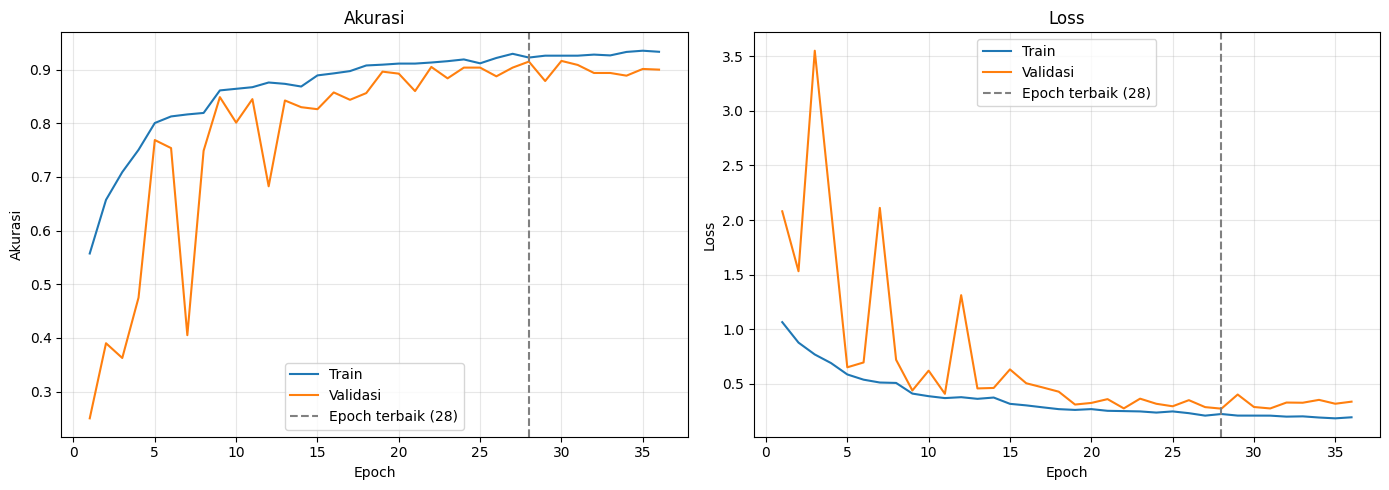

In [22]:
# Membuat plot akurasi dan loss (train vs validasi) dari hasil training
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

# epoch terbaik = val_loss terendah (bobot yang dikembalikan EarlyStopping)
best = int(np.argmin(val_loss)) + 1

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epochs_range, acc, label="Train")
ax[0].plot(epochs_range, val_acc, label="Validasi")
ax[0].axvline(best, color="gray", linestyle="--", label=f"Epoch terbaik ({best})")
ax[0].set_title("Akurasi")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Akurasi")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(epochs_range, loss, label="Train")
ax[1].plot(epochs_range, val_loss, label="Validasi")
ax[1].axvline(best, color="gray", linestyle="--", label=f"Epoch terbaik ({best})")
ax[1].set_title("Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Evaluasi akhir (augmentasi dan Dropout nonaktif, bobot terbaik dari EarlyStopping)
_, train_acc = model.evaluate(train_ds, verbose=0)
_, val_acc = model.evaluate(val_ds, verbose=0)
_, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Train: {train_acc:.4f} | Val: {val_acc:.4f} | Test: {test_acc:.4f}")

# Akurasi per kelas dan pasangan yang tertukar (test set)
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

cm = tf.math.confusion_matrix(y_true, y_pred, num_classes=NUM_CLASSES).numpy()
print("\nClass:", class_names)
print(cm)
for i, k in enumerate(class_names):
    print(f"{k:10} benar {cm[i, i]}/{cm[i].sum()} = {cm[i, i] / cm[i].sum():.2f}")

Train: 0.9323 | Val: 0.9150 | Test: 0.8850

Class: ['butterfly', 'cat', 'chicken', 'elephant']
[[191   8   0   1]
 [  7 178   9   6]
 [ 18  10 168   4]
 [ 12  14   3 171]]
butterfly  benar 191/200 = 0.95
cat        benar 178/200 = 0.89
chicken    benar 168/200 = 0.84
elephant   benar 171/200 = 0.85


## Konversi Model

In [24]:
# Model ekspor: sama dengan model latih, tanpa layer augmentasi (augmentasi hanya dipakai saat training)
export_model = Sequential(
    [layers.Input(shape=(*IMG, 3))] + [l for l in model.layers if l.name != "augmentasi"],
    name="model_ekspor",
)

# bukti: prediksi kedua model sama
for x, _ in test_ds.take(1):
    p1 = model.predict(x, verbose=0)
    p2 = export_model.predict(x, verbose=0)
print("Prediksi identik:", np.allclose(p1, p2, atol=1e-5))
export_model.summary()

Prediksi identik: True
Model: "model_ekspor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_1 (Rescaling)     (None, 224, 224, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 224, 224, 32)      864       
                                                                 
 batch_normalization (Batch  (None, 224, 224, 32)      128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 224, 224, 32)      0         
                                                                 
 conv2d_1 (Conv2D)           (None, 224, 224, 32)      9216      
                                                                 
 batch_normalization_1 (Bat  (None, 224, 224, 32)      128       
 chNormalization)              

In [25]:
# 1) SavedModel
export_model.save(PATHS["saved_model"])

# 2) TF-Lite + label.txt
tflite_model = tf.lite.TFLiteConverter.from_keras_model(export_model).convert()
with open(f"{PATHS['tflite']}/model.tflite", "wb") as f:
    f.write(tflite_model)
with open(f"{PATHS['tflite']}/label.txt", "w") as f:
    f.write("\n".join(class_names))

# 3) TFJS
tfjs.converters.save_keras_model(export_model, PATHS["tfjs"])

/usr/local/lib/python3.13/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


## Inference

Pilih satu atau beberapa gambar...


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Saving test.jpeg to test.jpeg


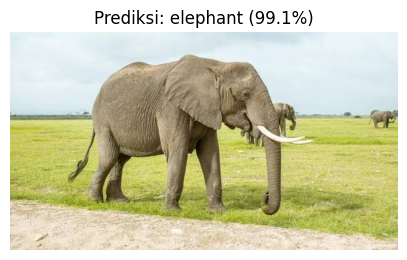

  elephant    99.1%
  cat          0.6%
  butterfly    0.3%
  chicken      0.0%



In [26]:
# Inference dengan model TF-Lite: upload gambar -> prediksi -> tampilkan gambar dan hasilnya

# Muat model dan label dari folder submission
interpreter = tf.lite.Interpreter(model_path=f"{PATHS['tflite']}/model.tflite")
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
tinggi, lebar = int(inp["shape"][1]), int(inp["shape"][2])

with open(f"{PATHS['tflite']}/label.txt") as f:
    labels = [baris.strip() for baris in f if baris.strip()]

def prediksi(path):
    img = Image.open(path).convert("RGB")
    # tanpa dibagi 255: normalisasi sudah ada di dalam model (layer Rescaling)
    x = np.array(img.resize((lebar, tinggi), Image.BILINEAR), dtype=np.float32)[None]
    interpreter.set_tensor(inp["index"], x)
    interpreter.invoke()
    return img, interpreter.get_tensor(out["index"])[0]

print("Pilih satu atau beberapa gambar...")
unggahan = files.upload()

for nama in unggahan:
    img, p = prediksi(nama)
    urut = np.argsort(p)[::-1]

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Prediksi: {labels[urut[0]]} ({p[urut[0]]*100:.1f}%)")
    plt.show()

    for i in urut:
        print(f"  {labels[i]:10} {p[i]*100:5.1f}%")
    print()